In [1]:
# 1. Import required libraries

import pandas as pd
import numpy as np
from pathlib import Path

# 2. Locate the dataset

file_name = "CAR DETAILS FROM CAR DEKHO.csv"

possible_paths = [
    Path("data/raw") / file_name,
    Path("../data/raw") / file_name
]

data_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

# 3. Load the dataset

if data_path is None:
    raise FileNotFoundError("Dataset not found!")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (4340, 8)


In [2]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [4]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(763)

# 1. Exploratory Data Analysis (EDA)

## 1.1 Dataset Overview

The CarDekho dataset contains 4,340 used-car records
and 8 features.

The target variable is selling_price, which represents
the resale price of each vehicle in INR.

The dataset contains numerical and categorical features.
Initial inspection identified 763 duplicate records and
no missing values.

## 1.2 Statistical Summary

This section presents descriptive statistics of the
numerical and categorical features in the dataset.

It helps identify the central tendency, distribution,
range, and variability of the dataset.

In [6]:
# Statistical summary of numerical columns

df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [7]:
# Statistical summary of categorical columns

df.describe(include='object')

,name,fuel,seller_type,transmission,owner
count,4340,4340,4340,4340,4340
unique,1491,5,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,69,2153,3244,3892,2832


In [8]:
# Number of unique values in each column

df.nunique()

name             1491
year               27
selling_price     445
km_driven         770
fuel                5
seller_type         3
transmission        2
owner               5
dtype: int64

In [9]:
# Unique values in categorical columns

categorical_columns = [
    'fuel',
    'seller_type',
    'transmission',
    'owner'
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


fuel:
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

seller_type:
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

transmission:
transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

owner:
owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64


In [10]:
# Display duplicate records

duplicates = df[df.duplicated(keep=False)]

print("Total duplicate-related rows:", len(duplicates))

duplicates.head(10)

Total duplicate-related rows: 1289


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner
9,Maruti Celerio Green VXI,2017,365000,78000,CNG,Individual,Manual,First Owner


## 1.3 Categorical Feature Analysis

This section explores the distribution of categorical
features in the CarDekho dataset.

The analysis helps us understand the frequency of
different fuel types, seller types, transmission types,
and ownership categories.

## 1.4 Investigation of Unusual Records

This section investigates unusually low and high values
in vehicle mileage and selling prices.

The objective is to identify potential data-quality
issues and extreme observations that may affect
machine learning model performance.

In [11]:
df.nsmallest(10, 'km_driven')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
1312,Mahindra Quanto C6,2014,250000,1,Diesel,Individual,Manual,Second Owner
1714,Ford Freestyle Titanium Diesel,2020,784000,101,Diesel,Dealer,Manual,Test Drive Car
1715,Ford Figo Titanium,2020,635000,101,Petrol,Dealer,Manual,Test Drive Car
1716,Ford Ecosport 1.5 Diesel Titanium,2020,1000000,101,Diesel,Dealer,Manual,Test Drive Car
552,Renault Duster 85PS Diesel RxL,2013,450000,1000,Diesel,Dealer,Manual,Second Owner
571,Renault Duster 85PS Diesel RxL,2013,450000,1000,Diesel,Dealer,Manual,Second Owner
590,Renault Duster 85PS Diesel RxL,2013,450000,1000,Diesel,Dealer,Manual,Second Owner
609,Renault Duster 85PS Diesel RxL,2013,450000,1000,Diesel,Dealer,Manual,Second Owner
897,Renault Duster 85PS Diesel RxL,2013,450000,1000,Diesel,Dealer,Manual,Second Owner
916,Renault Duster 85PS Diesel RxL,2013,450000,1000,Diesel,Dealer,Manual,Second Owner


In [12]:
df.nlargest(10, 'km_driven')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
1243,Maruti Swift VXI BSIII,2009,250000,806599,Petrol,Dealer,Manual,First Owner
525,Maruti SX4 S Cross DDiS 320 Delta,2016,665000,560000,Diesel,Dealer,Manual,First Owner
4184,Maruti SX4 S Cross DDiS 320 Delta,2016,665000,560000,Diesel,Dealer,Manual,First Owner
3679,Toyota Innova 2.5 G (Diesel) 7 Seater BS IV,2006,400000,400000,Diesel,Individual,Manual,Third Owner
69,Chevrolet Tavera Neo LS B3 - 7(C) seats BSIII,2010,280000,350000,Diesel,Individual,Manual,Second Owner
2394,Toyota Innova 2.5 V Diesel 8-seater,2009,350000,350000,Diesel,Individual,Manual,First Owner
3718,Toyota Innova 2.5 GX 8 STR BSIV,2009,420000,347089,Diesel,Dealer,Manual,First Owner
1674,Volkswagen Jetta 2.0 TDI Comfortline,2011,350000,312000,Diesel,Individual,Manual,Third Owner
1101,Tata Indica DLS,2006,85000,300000,Diesel,Individual,Manual,Second Owner
1659,Toyota Innova 2.5 G (Diesel) 8 Seater BS IV,2006,229999,300000,Diesel,Individual,Manual,First Owner


In [13]:
df.nsmallest(10, 'selling_price')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
2662,Ford Ikon 1.6 ZXI NXt,2005,20000,25000,Petrol,Individual,Manual,Second Owner
2495,Ford Ikon 1.4 ZXi,2000,22000,42743,Petrol,Dealer,Manual,Third Owner
2444,Maruti 800 EX,2004,30000,60000,Petrol,Individual,Manual,Third Owner
1832,Tata Nano LX SE,2012,35000,35000,Petrol,Individual,Manual,Third Owner
2849,Tata Nano Std BSII,2009,35000,50000,Petrol,Individual,Manual,Third Owner
3206,OpelCorsa 1.4 GL,2002,35000,100000,Petrol,Individual,Manual,Third Owner
4290,Maruti 800 Std,2004,37500,90000,Petrol,Individual,Manual,Second Owner
137,Maruti 800 Std,1998,40000,40000,Petrol,Individual,Manual,Fourth & Above Owner
877,Tata Nano Std,2011,40000,19000,Petrol,Individual,Manual,First Owner
1350,Maruti 800 EX,2001,40000,30000,Petrol,Individual,Manual,First Owner


In [14]:
df.nlargest(10, 'selling_price')

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
3872,Audi RS7 2015-2019 Sportback Performance,2016,8900000,13000,Petrol,Dealer,Automatic,First Owner
89,Mercedes-Benz S-Class S 350d Connoisseurs Edition,2017,8150000,6500,Diesel,Dealer,Automatic,First Owner
3969,Mercedes-Benz GLS 2016-2020 350d 4MATIC,2016,5500000,77350,Diesel,Dealer,Automatic,First Owner
555,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Dealer,Automatic,First Owner
574,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Dealer,Automatic,First Owner
593,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Dealer,Automatic,First Owner
612,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Dealer,Automatic,First Owner
900,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Dealer,Automatic,First Owner
919,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Dealer,Automatic,First Owner
1023,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Dealer,Automatic,First Owner


### Observations and Findings

1. The dataset contains unusually low mileage records,
   including a vehicle with only 1 km driven.

2. Some low-mileage vehicles are classified as Test
   Drive Cars, which may explain their low usage.

3. Several vehicles have unusually high mileage,
   with the maximum reaching 806,599 km.

4. The selling price ranges from ₹20,000 to ₹89,00,000.

5. Luxury vehicles such as Audi, BMW and Mercedes-Benz
   account for some of the highest selling prices.

6. These observations require further investigation
   before deciding on data-cleaning strategies.

## 1.5 Duplicate Record Analysis

This section identifies exact duplicate records
in the original dataset and examines their frequency.

Duplicate records are investigated to avoid redundant
observations affecting model training and evaluation.

In [15]:
# Count exact duplicate occurrences

duplicate_count = df.duplicated().sum()

# Count all rows belonging to duplicate groups

duplicate_rows = df.duplicated(keep=False).sum()

print("Original dataset size:", len(df))
print("Additional duplicate occurrences:", duplicate_count)
print("Total rows involved in duplicate groups:", duplicate_rows)
print("Unique records after deduplication:", len(df) - duplicate_count)

Original dataset size: 4340
Additional duplicate occurrences: 763
Total rows involved in duplicate groups: 1289
Unique records after deduplication: 3577


In [16]:
# Extract duplicate records

duplicate_records = df[df.duplicated(keep=False)]

duplicate_records.head(20)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner
9,Maruti Celerio Green VXI,2017,365000,78000,CNG,Individual,Manual,First Owner


In [17]:
# Find the most frequently repeated records

duplicate_records.value_counts().head(10)

name                                  year  selling_price  km_driven  fuel    seller_type       transmission  owner       
Audi A4 3.0 TDI Quattro               2013  1580000        86000      Diesel  Dealer            Automatic     First Owner     12
Hyundai Verna 1.6 VTVT SX             2015  760000         55340      Petrol  Trustmark Dealer  Manual        First Owner     12
Hyundai Grand i10 1.2 Kappa Magna AT  2017  550000         19890      Petrol  Dealer            Automatic     First Owner     12
Hyundai Creta 1.6 CRDi SX             2016  535000         52600      Diesel  Individual        Manual        First Owner     12
Hyundai Santro GS                     2005  80000          56580      Petrol  Dealer            Manual        First Owner     12
Maruti S-Cross Zeta DDiS 200 SH       2015  750000         45974      Diesel  Trustmark Dealer  Manual        First Owner     12
Maruti SX4 Vxi BSIV                   2012  225000         110000     Petrol  Individual        Manual 

### Observations and Findings

1. The original dataset contains 4,340 records.

2. A total of 763 additional duplicate occurrences
   were identified.

3. There are 1,289 rows belonging to duplicate groups.

4. Removing exact duplicate occurrences would leave
   3,577 unique records.

5. Several vehicle records appear multiple times
   with identical values across all eight columns.

6. Since the dataset does not contain unique listing
   identifiers, the original reason for these repeated
   records cannot be confirmed.

Exact duplicates will be removed during preprocessing
to avoid repeatedly weighting identical observations.

# 2. Data Preprocessing

## 2.1 Removing Duplicate Records

Exact duplicate records are removed from the dataset
to eliminate repeated observations.

The original dataset is preserved, and the cleaned
dataset is stored separately for further processing.

In [18]:
# Create a cleaned copy of the original dataset

df_clean = df.drop_duplicates().copy()

# Reset index after removing duplicates

df_clean.reset_index(drop=True, inplace=True)

# Verify the results

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Original dataset shape: (4340, 8)
Cleaned dataset shape: (3577, 8)
Remaining duplicates: 0


In [19]:
# Save cleaned dataset

df_clean.to_csv(
    "../data/processed/used_cars_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 1.6 Univariate Analysis

Univariate analysis examines individual features
to understand their distributions, frequencies,
and underlying patterns.

This analysis helps identify skewness, dominant
categories, and potential outliers in the dataset.

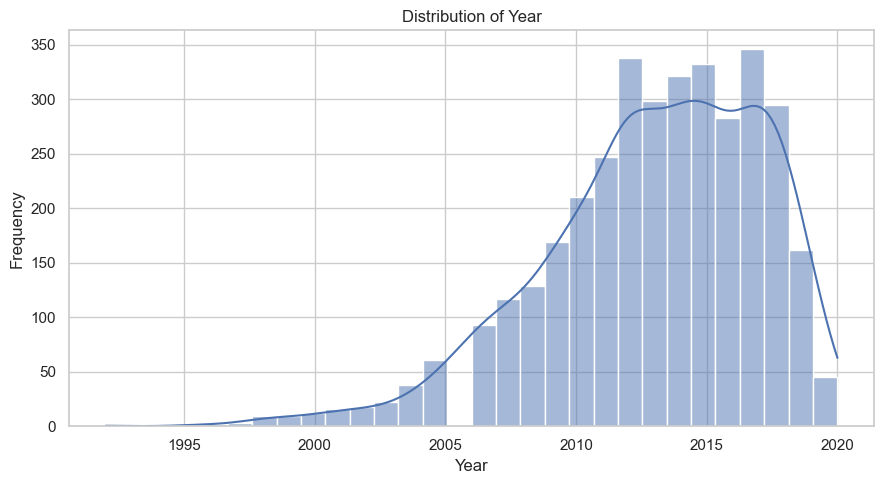

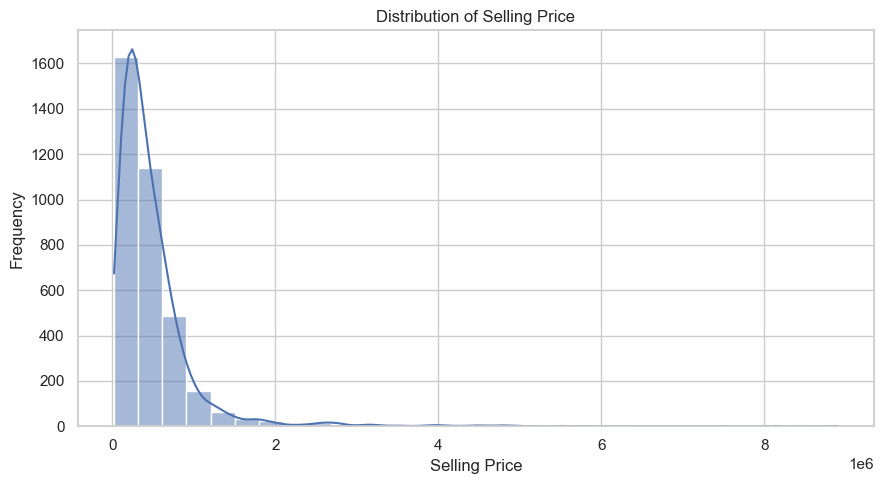

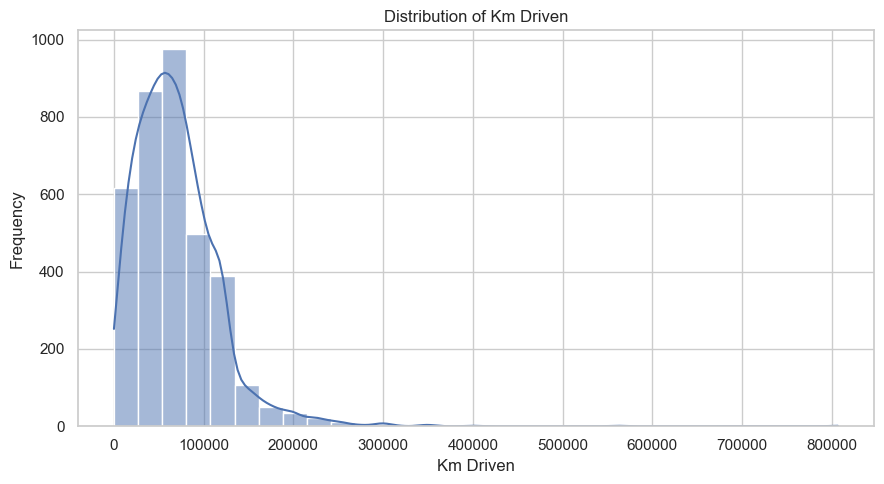

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

numerical_columns = [
    'year',
    'selling_price',
    'km_driven'
]

for col in numerical_columns:
    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=df_clean,
        x=col,
        bins=30,
        kde=True
    )

    plt.title(f'Distribution of {col.replace("_", " ").title()}')
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

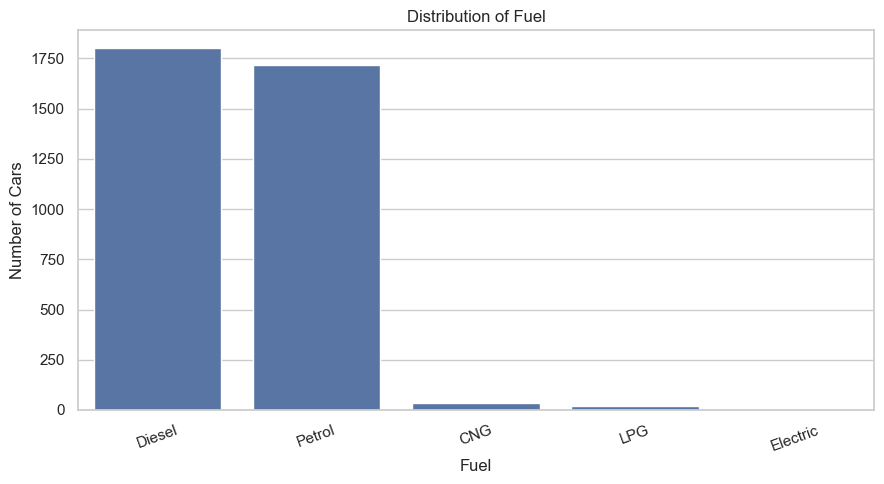

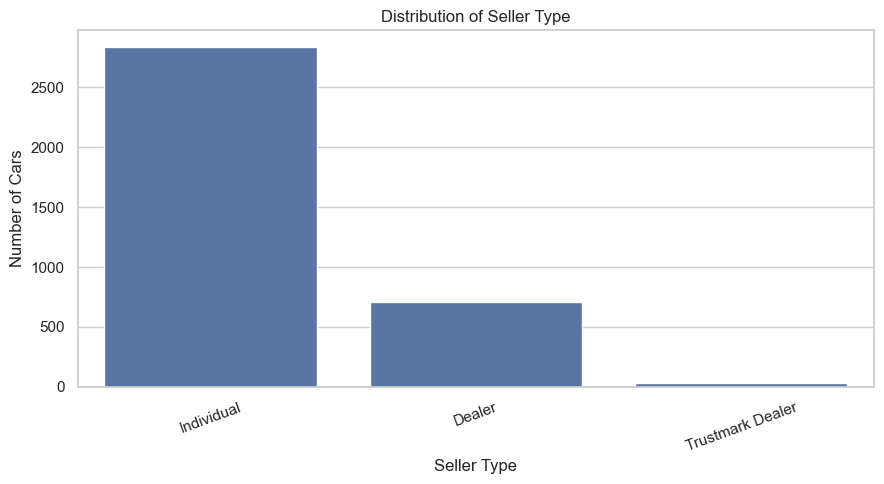

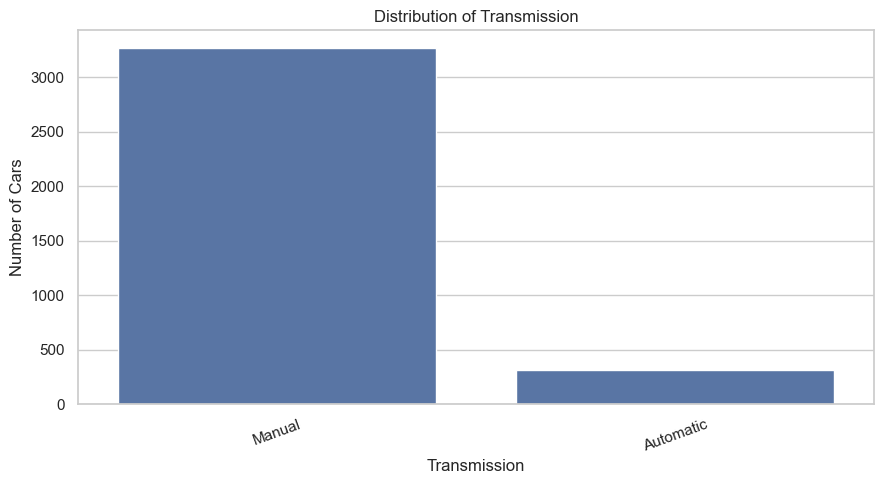

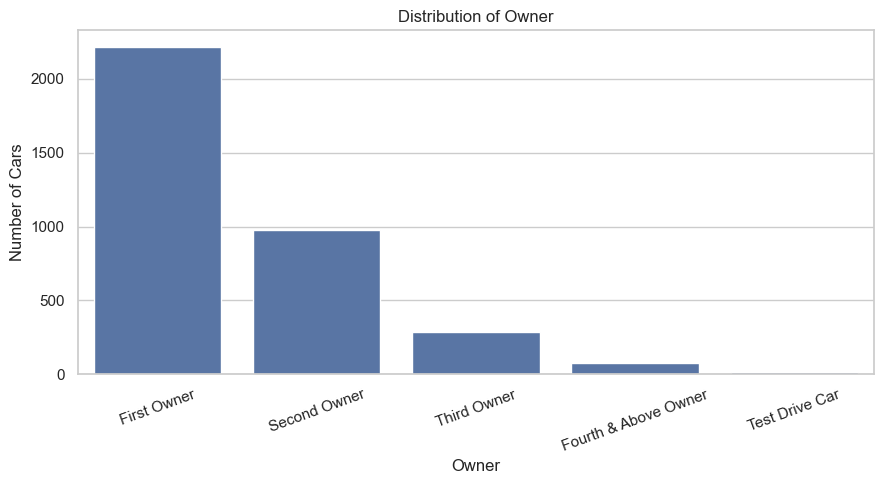

In [21]:
categorical_columns = [
    'fuel',
    'seller_type',
    'transmission',
    'owner'
]

for col in categorical_columns:
    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df_clean,
        x=col,
        order=df_clean[col].value_counts().index
    )

    plt.title(f'Distribution of {col.replace("_", " ").title()}')
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel('Number of Cars')
    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

### Observations and Findings

**Numerical Features:**

1. **Year:** Most vehicles were manufactured between 2012 and 2018, indicating a concentration of relatively newer used cars.

2. **Selling Price:** The distribution is strongly right-skewed, with most vehicles concentrated in lower price ranges and a few expensive luxury vehicles forming a long right tail.

3. **Kilometres Driven:** Most vehicles have moderate mileage, while a small number have extremely high mileage, creating a right-skewed distribution.

**Categorical Features:**

4. **Fuel:** Diesel and Petrol vehicles dominate the dataset, while CNG, LPG and Electric vehicles have significantly fewer records.

5. **Seller Type:** Individual sellers account for the majority of listings, followed by Dealers and Trustmark Dealers.

6. **Transmission:** Manual transmission vehicles are significantly more common than Automatic vehicles.

7. **Owner:** First Owner vehicles dominate the dataset, followed by Second Owner vehicles. Vehicles with three or more previous owners are considerably less frequent.

**Overall Conclusion:**

The dataset contains noticeable differences in feature distributions, including right-skewed numerical variables and imbalanced categorical variables. These characteristics will be considered during feature engineering, preprocessing and model development.

## 1.7 Cleaned Dataset Verification

In [32]:
df_clean = pd.read_csv("../data/processed/used_cars_cleaned.csv")

print("Cleaned Dataset Shape:", df_clean.shape)
print("Remaining Duplicates:", df_clean.duplicated().sum())
print("Missing Values:", df_clean.isnull().sum().sum())

Cleaned Dataset Shape: (3577, 8)
Remaining Duplicates: 0
Missing Values: 0


## 1.8 Bivariate Analysis

Bivariate analysis is used to examine the relationship between two variables. In this section, we investigate how numerical and categorical features influence the selling price of used cars.

### 1.8.1 Year vs Selling Price

This analysis examines how the manufacturing year of a car affects its selling price.

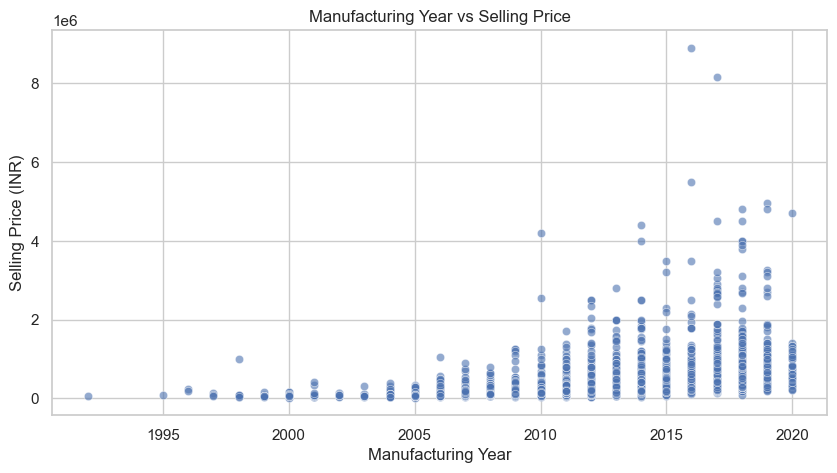

In [33]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x="year",
    y="selling_price",
    alpha=0.6
)

plt.title("Manufacturing Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price (INR)")
plt.show()

### 1.8.2 Kilometres Driven vs Selling Price

This analysis investigates whether cars with higher mileage tend to have lower selling prices.

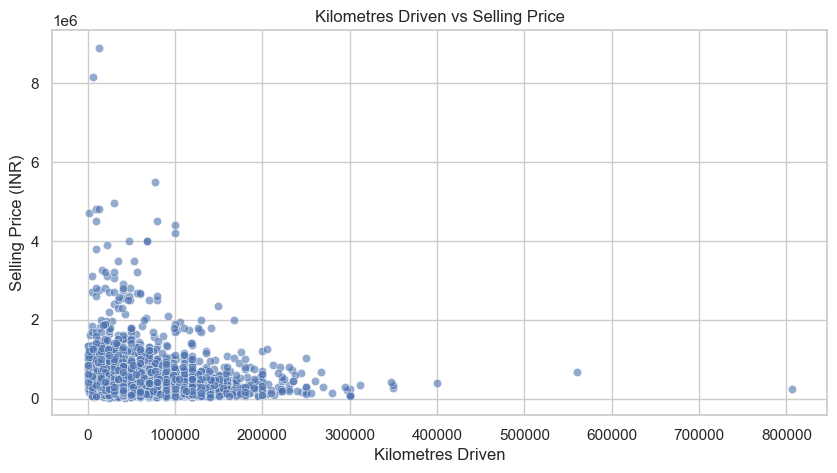

In [34]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x="km_driven",
    y="selling_price",
    alpha=0.6
)

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (INR)")
plt.show()

### 1.8.3 Fuel Type vs Selling Price

This analysis compares the selling price distribution across different fuel types.

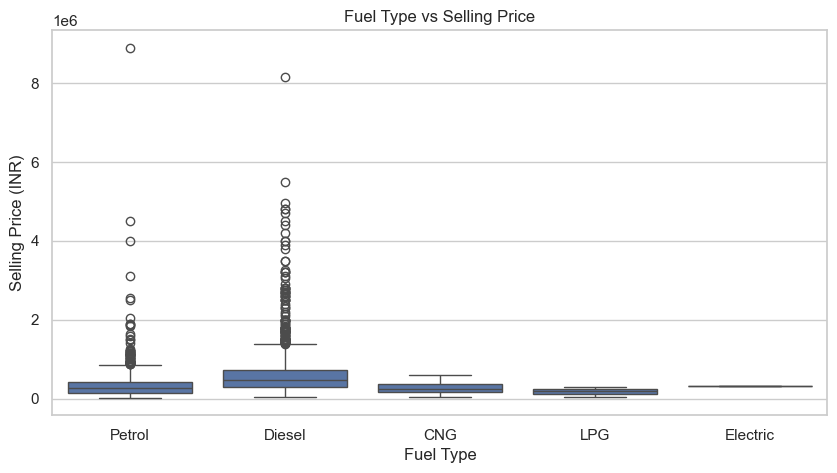

In [35]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x="fuel",
    y="selling_price"
)

plt.title("Fuel Type vs Selling Price")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (INR)")
plt.show()

### 1.8.4 Transmission vs Selling Price

This analysis compares the selling prices of manual and automatic transmission vehicles.

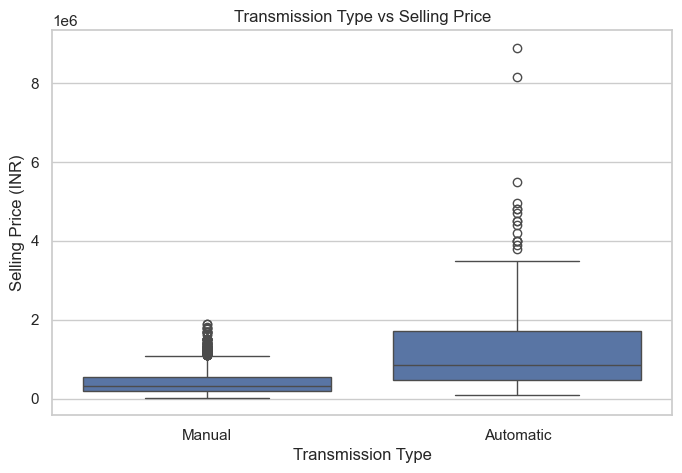

In [36]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="transmission",
    y="selling_price"
)

plt.title("Transmission Type vs Selling Price")
plt.xlabel("Transmission Type")
plt.ylabel("Selling Price (INR)")
plt.show()

### 1.8.5 Owner Type vs Selling Price

This analysis examines how the number of previous owners is associated with the selling price of used cars.

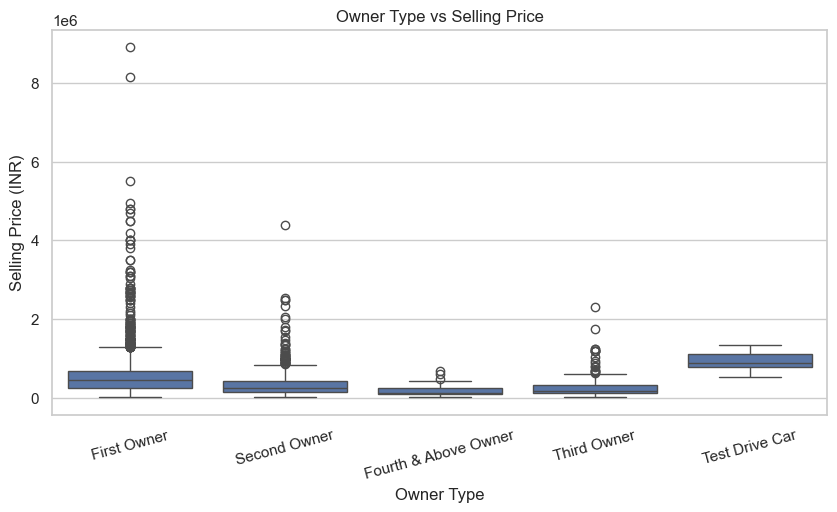

In [37]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x="owner",
    y="selling_price"
)

plt.title("Owner Type vs Selling Price")
plt.xlabel("Owner Type")
plt.ylabel("Selling Price (INR)")
plt.xticks(rotation=15)
plt.show()

### 1.8.6 Bivariate Analysis – Key Findings

The bivariate analysis revealed the following relationships between car features and selling price:

1. **Manufacturing Year:** Newer vehicles generally have higher selling prices compared to older vehicles.

2. **Kilometres Driven:** Vehicles with higher kilometres driven generally tend to have lower selling prices.

3. **Fuel Type:** Diesel vehicles show a higher median selling price than petrol vehicles. However, CNG, LPG, and electric categories have fewer observations.

4. **Transmission Type:** Automatic vehicles have a higher median selling price and wider price distribution compared to manual vehicles.

5. **Owner Type:** First-owner vehicles generally have higher median selling prices than vehicles with multiple previous owners. Test Drive Cars show a higher median, but this category contains very few records.

**Overall Conclusion:**

Manufacturing year, kilometres driven, fuel type, transmission type, and ownership are associated with variations in used-car selling prices. These features may provide useful information for building the price prediction model.

## 1.9 Correlation Analysis

Correlation analysis is used to understand the strength and direction of relationships between numerical variables in the dataset. A correlation heatmap is used to visualise these relationships.

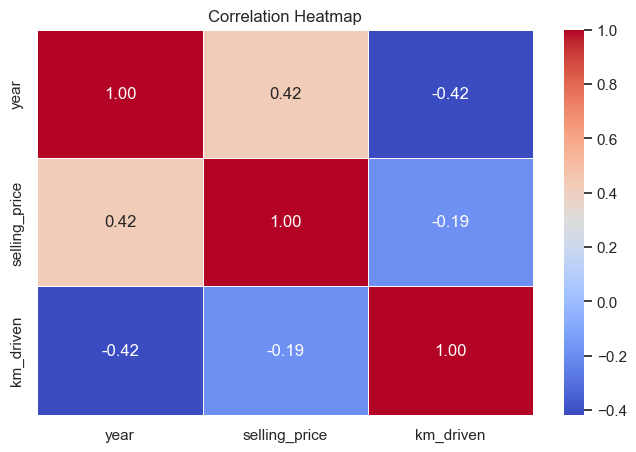

In [38]:
# Calculate correlation between numerical variables
correlation_matrix = df_clean.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

### 1.10 Correlation Analysis – Key Findings

The correlation heatmap reveals the following relationships:

1. Manufacturing year has a moderate positive correlation (0.42) with selling price, indicating that newer vehicles generally tend to have higher prices.

2. Kilometres driven has a weak negative correlation (-0.19) with selling price, suggesting that vehicles with higher mileage tend to have slightly lower prices.

3. Manufacturing year and kilometres driven have a moderate negative correlation (-0.42), indicating that newer vehicles generally have lower accumulated mileage.

**Conclusion:**

Manufacturing year shows a stronger linear relationship with selling price than kilometres driven. However, correlation alone cannot determine the importance of features in a machine learning model.

# 2. Exploratory Data Analysis – Overall Summary

The Exploratory Data Analysis was performed to understand the structure, quality, distribution and relationships within the CarDekho used car dataset.

The following key observations were identified:

1. The original dataset contained 4,340 records and 8 features.
2. No missing values were found.
3. A total of 763 duplicate occurrences were identified and removed, resulting in 3,577 unique records.
4. Selling prices and kilometres driven showed right-skewed distributions.
5. Newer vehicles generally showed higher selling prices.
6. Vehicles with automatic transmission and diesel fuel showed higher median selling prices in this dataset.
7. Manufacturing year had a moderate positive correlation (0.42) with selling price, while kilometres driven had a weak negative correlation (-0.19).

**Final Conclusion:**

The dataset was successfully inspected, analysed and cleaned. The findings provide an initial understanding of the factors associated with used car prices. The cleaned dataset is ready for the next stage of preprocessing and machine learning model development.